# Seam Carving Notebook
**Sections**
1) Introduction: Purpose of Seam Carving
2) Implementation and Dynamic Programming
4) Practice Problem

# 1) Introduction: Purpose of Seam Carving
**The purpose of seam carving is to resize an image.** You frequently use more common resizing techniques such as cropping (cropping an image on your phone) or scaling (resizing an image in PowerPoint). Resizing techniques all come with their pros and cons; seam carving is no different.
| Technique | Pro | Con |
|---|---|---|
| **Cropping** | Preserves the original pixels of retained content | May cut off important content near image edges |
| **Non-Uniform Scaling** | Preserves all image content | Distorts object shapes and proportions |
| **Seam Carving** | Prioritizes preserving important objects and their shapes | Can introduce distortions and visual artifacts |

Run the code below to see the output of each resizing technique.

Original Image Info:
<class 'numpy.ndarray'>
(230, 410, 3)
float32
0.12941177 0.9843138

Cropped Image Info:
<class 'numpy.ndarray'>
(230, 287, 3)
float32
0.14117648 0.9843138

Scaled Image Info:
<class 'numpy.ndarray'>
(230, 287, 3)
float32
0.13193303 0.9817919



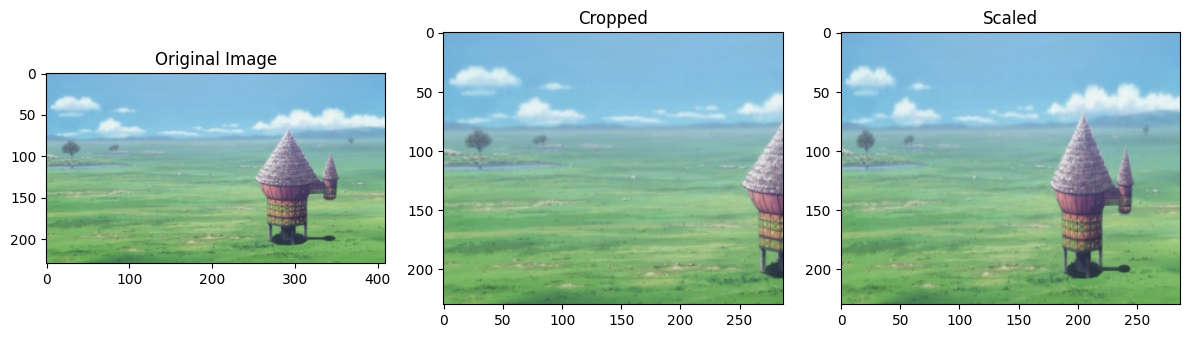

In [ ]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, util, color, transform
from scipy import ndimage as ndi
from skimage.util import img_as_ubyte

def show_images(images, titles=None):
    n = len(images)
    fig, ax = plt.subplots(1, n, figsize=(4*n, 4), squeeze=False)

    for i in range(n):
        ax[0, i].imshow(images[i], cmap='gray')

        if titles is not None:
            ax[0, i].set_title(titles[i])

    plt.tight_layout()
    plt.show()

def print_imginfo(I):
    print(type(I))
    print(I.shape)
    print(I.dtype)
    print(I.min(), I.max())

I = util.img_as_float32(io.imread("images/field.jpg")[..., :3])

print("Original Image Info:")
print_imginfo(I)
print()

I_crop = I[:, :287]
print("Cropped Image Info:")
print_imginfo(I_crop)
print()

I_scale = transform.resize(I, (230, 287), anti_aliasing=True)
print("Scaled Image Info:")
print_imginfo(I_scale)
print()


show_images([I, I_crop, I_scale], ["Original Image", "Cropped", "Scaled"])



With cropping, you preserve the exact pixels of the remaining image, but cutting off important objects near the edge is often unavoidable. Non-uniform scaling will preserve all important objects, but can distort these objects. You can see how seam carving solves these issues in the above images. In the cropped image, a portion of the tower, a tree in the background, and the rightmost cloud are all cut from the image. The scaled image retains these components, but the tower is stretched vertically, making it look much thinner. In the seam carved image, we have reduced the image to the same size as the cropped and scaled image while retaining all the key objects of the original image.


### Recap/Key Ideas
The goal of seam carving is to resize an image while preserving important objects without stretching or squeezing. Seam carving accomplishes this by assigning pixels an "importance" value, then repeatedly finding the least important "seam" in the image and removing it.

**A seam is a line of connected pixels that spans an image edge to edge (either top-to-bottom or side-to-side).** A seam can be horizontal or vertical, depending on which way you want to resize. A seam is one pixel wide; a vertical seam selects exactly one pixel per row, moving at most one column between adjacent rows. Vice-versa for horizontal seams.

**Seam carving is a resizing technique which preserves important parts of an image.** Once you understand this, its just a matter of implementation. You might be asking "what does it mean to be *an important part of an image?*". This is a great question and determining which parts of an image are important and which are not is the main challenge of seam carving. Section 3 will go into detail on this challenge, but first let's get a better understanding of the technique in Section 2, which works through a simple implementation of seam carving. **Note: Section 3 still needs to be added for final presentation. It's not required to understand seam carving or complete the practice.**

# 2) Implementation and Dynamic Programming

### Seam Carving Steps
1) Calculate energy
2) Find lowest energy seam using dynamic programming
3) Remove the low energy seam
4) Repeat until desired size is reached

### 2.1) Calculate energy
In this case, high importance or high energy pixels are going to be determined by finding edges/gradients. Pixels in an area of relatively uniform intensity are low energy while pixels near edges are high energy. To calculate energy, we are using a Sobel filter.

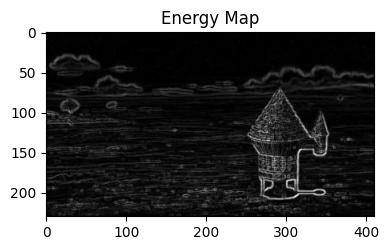

In [ ]:
def calculate_energy(I):
  gray = None
  if I.ndim == 3:
    gray = color.rgb2gray(I)
  else:
    gray = I.copy()
  kernel_x = np.array([ [1.0, 0.0, -1.0],
                        [2.0, 0.0, -2.0],
                        [1.0, 0.0, -1.0],
  ])

  kernel_y = np.array([ [1.0, 2.0, 1.0],
                        [0.0, 0.0, 0.0],
                        [-1.0, -2.0, -1.0],
  ])

  convolved = np.abs(ndi.convolve(gray, kernel_x)) + np.abs(ndi.convolve(gray, kernel_y))
  return convolved

energy = calculate_energy(I)
show_images([energy], ["Energy Map"])

### 2.2) Find lowest energy seam
We use dynamic programming to find the smallest energy seam. The first step is to make a matrix M where each element represents the cumulative energy required to reach that pixel from the top of the image. The intuition is once that matrix is complete, the bottom row will tell us the total energy required to get to that pixel. From there, you can just backtrack from the bottom pixel to the top row, and you will have your minimum seam.

Again, the idea is to create a matrix M in the same shape as the energy map E. Any entry in M is saying "from the top row of the image, how much total energy is required to reach this pixel?". This means that the first row of M should be exactly the  same as the first row of E. On row 2, you look at pixels up and to the left, directly up, and up and to the right, of the current pixel, and add the smallest of those 3 values to the current energy value. You can continue this process until M is completely filled. You then look at the bottom row of M and select the smallest cumulative energy. Think of the bottom row of M as saying "what is the minimum amount of energy required to go from the ANY pixel on the top row to this specific pixel on the bottom row?". By definition, the minimum value on the bottom row would be the energy of the minimum seam, and the pixel is the endpoint of the minimum seam. From there, you just need to backtrack to the top to identify the entire seam.

Exception ignored in: <function PluginV3.__del__ at 0x7ad883ac3560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/imageio/core/v3_plugin_api.py", line 370, in __del__
    self.close()
  File "/usr/local/lib/python3.13/dist-packages/imageio/plugins/pillow.py", line 145, in close
    self._flush_writer()
  File "/usr/local/lib/python3.13/dist-packages/imageio/plugins/pillow.py", line 489, in _flush_writer
    primary_image.save(self._request.get_file(), **self.save_args)
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 2546, in save
    raise ValueError(msg) from e
ValueError: unknown file extension: 


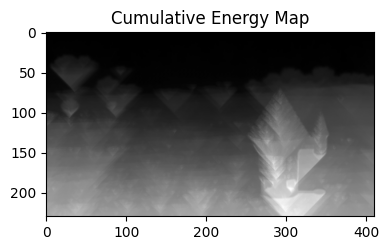

In [ ]:
def minimum_seam(I):
  rows, cols, _ = I.shape
  energy = calculate_energy(I)

  M = energy.copy()

  for r in range(1, rows):
    for c in range(0, cols):
      if c == 0:
          min_energy = np.min(M[r - 1, c:c + 2])
      elif c == cols - 1:
          min_energy = np.min(M[r - 1, c - 1:c + 1])
      else:
          min_energy = np.min(M[r - 1, c - 1:c + 2])
      M[r, c]+=min_energy
  return M

M = minimum_seam(I)
show_images([M], ["Cumulative Energy Map"])

### 2.3) Remove the low energy seam
Although a seam can run diagonally through an image, a seam is defined to be a single pixel wide. So when you remove a seam, you are reducing the image size (either vertically or horizontally) by one pixel.

### 2.4) Repeat
We repeatedly calculate the lowest energy seam and remove it. If you want to reduce image width by 200 pixels, 200 vertical seams would need to be removed. In the code below, we are reducing the image width by 160 pixels, so 160 iterations are performed.

100%|██████████| 123/123 [00:47<00:00,  2.57it/s]


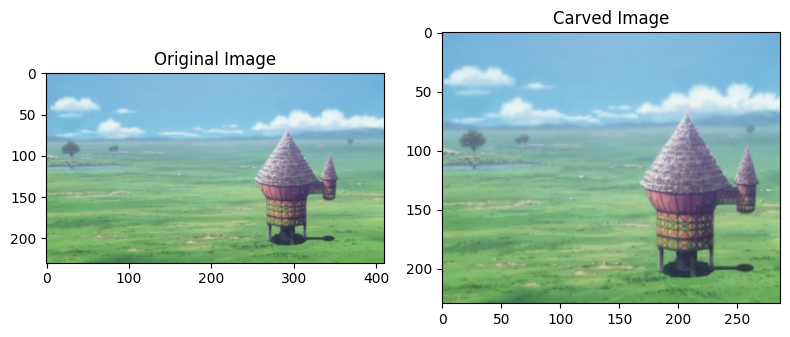

In [ ]:
from tqdm import trange
def carve_column(I):
    rows, cols, _ = I.shape

    M = minimum_seam(I)

    # truth mask on whether to delete a pixel
    mask = np.ones((rows, cols), dtype=bool)

    # find the smallest accumilated energy pixel on the last row
    j = np.argmin(M[-1])

    for i in reversed(range(rows)):
        mask[i, j] = False

        if i > 0:
            left = max(0, j - 1)
            right = min(cols, j + 2)

            j = left + np.argmin(M[i - 1, left:right])


    # apply the mask, but also reshape to make it a 2d array afterwards
    if I.ndim == 3:
        carved = I[mask].reshape(rows, cols - 1, I.shape[2])
    else:
        carved = I[mask].reshape(rows, cols - 1)

    return carved

def crop(I, scale):
  rows, cols, _ = I.shape
  new_cols = int(scale * cols)

  for i in trange(cols - new_cols):
      I = carve_column(I)

  return I


I = io.imread("images/field.jpg")
out = crop(I.copy(), 0.70)
show_images([I, out], ["Original Image", "Carved Image"])

In [ ]:
# Mr.ChatGPT by OpenAI aided in creating these gif creation functions

import matplotlib.pyplot as plt
import imageio.v2 as imageio
from tqdm import trange

def pad_frame(frame, rows, cols):
    padded = np.zeros((rows, cols, frame.shape[2]), dtype=frame.dtype)
    padded[:, :frame.shape[1]] = frame
    return padded

def carve_column_gif(I):
    rows, cols, _ = I.shape

    M = minimum_seam(I)

    mask = np.ones((rows, cols), dtype=bool)

    j = np.argmin(M[-1])

    for i in reversed(range(rows)):
        mask[i, j] = False

        if i > 0:
            left = max(0, j - 1)
            right = min(cols, j + 2)

            j = left + np.argmin(M[i - 1, left:right])

    if I.ndim == 3:
        carved = I[mask].reshape(rows, cols - 1, I.shape[2])
    else:
        carved = I[mask].reshape(rows, cols - 1)

    highlighted = I.copy()
    highlighted[~mask] = [255, 0, 0]

    return carved, highlighted

def crop_gif(I, scale, name="seam_carving.gif"):
    rows, cols, _ = I.shape
    new_cols = int(scale * cols)

    frames = []

    fig, ax = plt.subplots()
    ax.axis("off")

    for i in trange(cols - new_cols):
        carved, highlighted = carve_column_gif(I)

        ax.clear()
        ax.axis("off")
        ax.imshow(highlighted)
        plt.pause(0.01)

        frames.append(pad_frame(highlighted.copy(), rows, cols))

        ax.clear()
        ax.axis("off")
        ax.imshow(carved)
        plt.pause(0.01)

        frames.append(pad_frame(carved.copy(), rows, cols))

        I = carved

    plt.close(fig)

    imageio.mimsave(name, frames, duration=0.2, loop=0)

    return I

  0%|          | 0/123 [00:00<?, ?it/s]

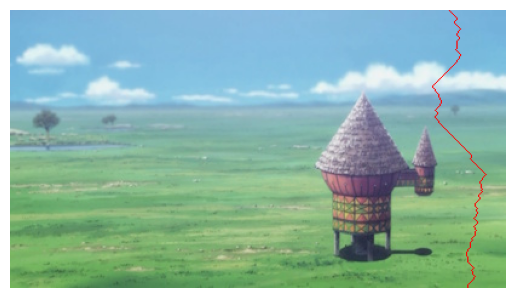

100%|██████████| 123/123 [00:57<00:00,  2.13it/s]


In [ ]:
I = io.imread("images/field.jpg")
out = crop_gif(I.copy(), 0.70, "field.gif")

# 3) Other Cases

100%|██████████| 137/137 [01:07<00:00,  2.04it/s]


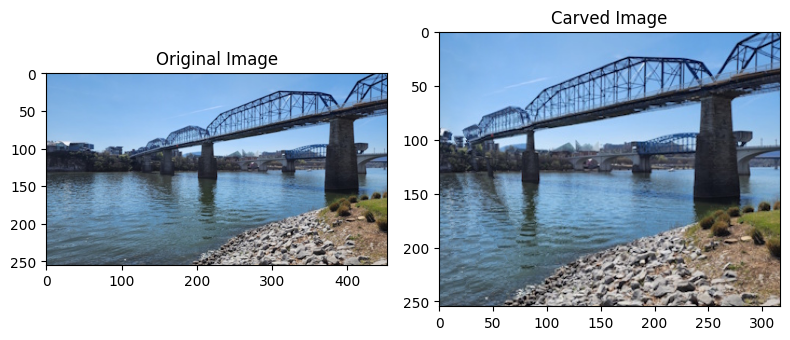

In [ ]:
I = io.imread("images/chatt-bridge.jpg")
out = crop(I.copy(), 0.70)
show_images([I, out], ["Original Image", "Carved Image"])

100%|██████████| 59/59 [00:31<00:00,  1.90it/s]


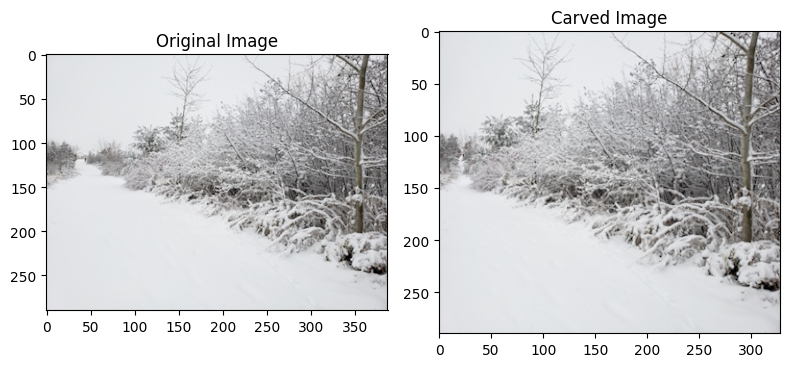

In [ ]:
I = io.imread("images/winter.jpg")
out = crop(I.copy(), 0.85)
show_images([I, out], ["Original Image", "Carved Image"])

100%|██████████| 69/69 [00:23<00:00,  2.94it/s]


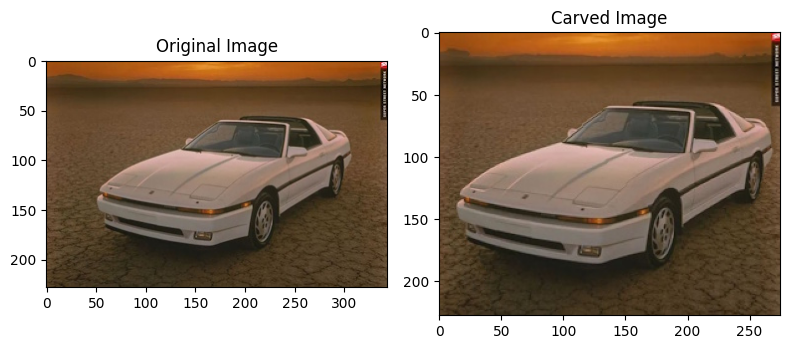

In [ ]:
I = io.imread("images/supra.jpg")
out = crop(I.copy(), 0.80)
show_images([I, out], ["Original Image", "Carved Image"])

100%|██████████| 53/53 [00:32<00:00,  1.63it/s]


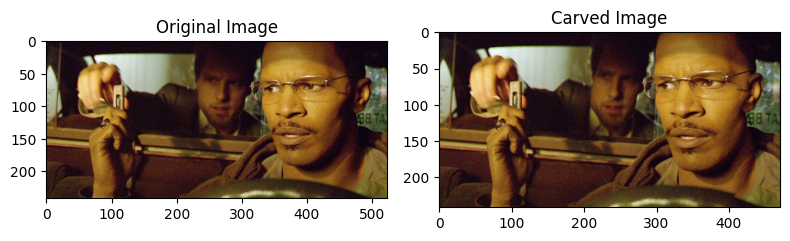

  0%|          | 0/53 [00:00<?, ?it/s]

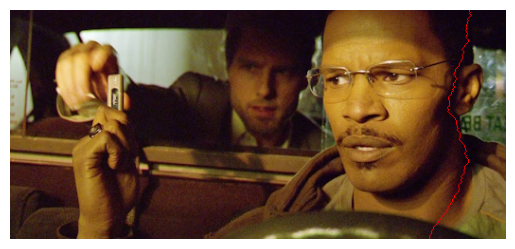

100%|██████████| 53/53 [00:33<00:00,  1.57it/s]


In [ ]:
I = io.imread("images/collateral.jpg")
out = crop(I.copy(), 0.90)
show_images([I, out], ["Original Image", "Carved Image"])
out = crop_gif(I.copy(), 0.90, "collateral.gif")

100%|██████████| 11/11 [00:02<00:00,  4.02it/s]


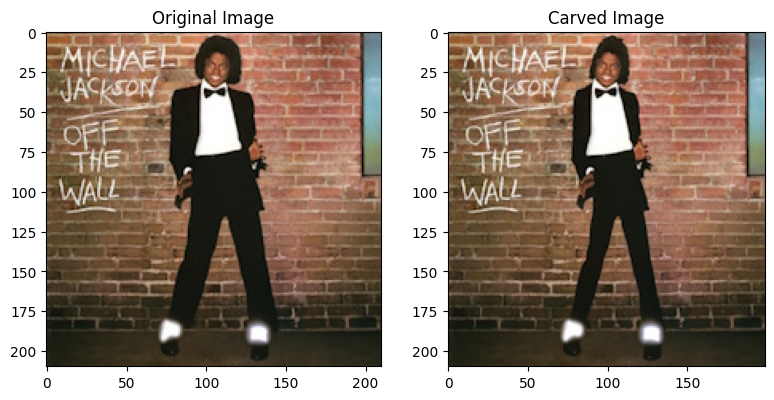

  0%|          | 0/11 [00:00<?, ?it/s]

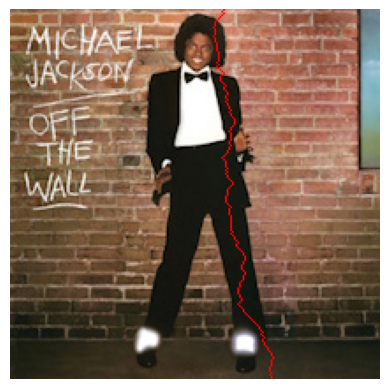

100%|██████████| 11/11 [00:02<00:00,  3.99it/s]


In [ ]:
I = io.imread("images/mj-off-the-wall.jpg")
out = crop(I.copy(), 0.95)
show_images([I, out], ["Original Image", "Carved Image"])
out = crop_gif(I.copy(), 0.95, "OTW.gif")

# 4) Practice Problem
Below is a 5x5 energy map. The goal is to find and remove the minimum energy seam from this energy map. Remember that a vertical seam contains exactly one pixel per row and its column can change by at most one position between rows.
You need to use dynamic programming to find the seam. The steps are as follows:
1) Initialize: The first row of cumulative energy M is identical to the first row of the original energy map E
2) Accumulate: Work your way down row by row, pixel by pixel. For each pixel add its energy value to the smallest cumulative energy seen in the neighbors above that pixel (look above and to the left, directly above, and above and to the right in the Matrix M)
3) Find the endpoint: The smallest value in the bottom row of M is where the minimum-energy seam ends
4) Backtrack: Starting at that endpoint, repeatedly choose the lowest energy pixel of the 3 pixels above the endpoint pixel

Step 1-3 work to find the minimum energy neighbor, the minimum seam endpoint, and then remove that seam.

np.argmin() returns the index of the smallest value
np.min() returns the smallest value

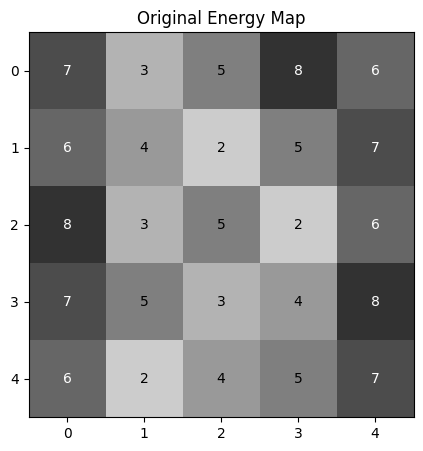

In [ ]:
# 5x5 Energy Map
E = np.array([
    [7, 3, 5, 8, 6],
    [6, 4, 2, 5, 7],
    [8, 3, 5, 2, 6],
    [7, 5, 3, 4, 8],
    [6, 2, 4, 5, 7]
])

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(E, cmap="gray_r", vmin=0, vmax=10)

for i in range(5):
    for j in range(5):
        ax.text(j, i, E[i, j],
                ha="center", va="center",
                color="white" if E[i, j] >= 6 else "black")

ax.set_xticks(range(5))
ax.set_yticks(range(5))
ax.set_title("Original Energy Map")
plt.show()

Cumulative Energy Map:
[[ 7  3  5  8  6]
 [ 9  7  5 10 13]
 [15  8 10  7 16]
 [15 13 10 11 15]
 [19 12 14 15 18]]


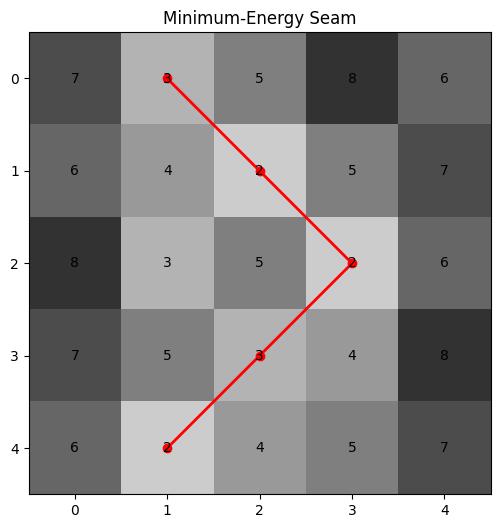

Minimum seam energy: 12


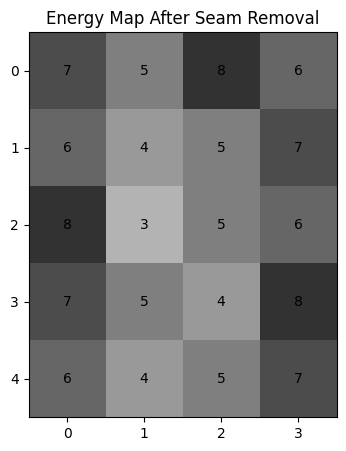

Original shape: (5, 5)
Carved shape: (5, 4)


In [ ]:
rows, cols = E.shape

# M stores the minimum cumulative energy to reach each pixel
M = np.zeros_like(E)

# Initialize the first row of cumulative energy
M[0] = E[0]

# Compute cumulative energy using dynamic programming
for i in range(1, rows):
    for j in range(cols):

        # Find the minimum energy among valid predecessors
        left = max(0, j - 1)
        right = min(cols, j + 2)

        min_previous = np.min(M[i-1, left:right])

        # Calculate cumulative energy at this pixel
        M[i, j] = E[i, j] + min_previous

print("Cumulative Energy Map:")
print(M)

# Find the ending column of the minimum-energy seam
j = np.argmin(M[-1])

# Backtrack to recover the seam
seam = np.zeros(rows, dtype=int)

for i in reversed(range(rows)):
    seam[i] = j

    if i > 0:
        left = max(0, j - 1)
        right = min(cols, j + 2)

        # Find the previous column in the seam
        j = left + np.argmin(M[i-1, left:right])

# Visualize the energy map and selected seam
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(E, cmap="gray_r", vmin=0, vmax=10)

for i in range(rows):
    for j in range(cols):
        ax.text(j, i, E[i, j], ha="center", va="center")

ax.plot(seam, np.arange(rows), "r-o", linewidth=2)

ax.set_title("Minimum-Energy Seam")
ax.set_xticks(range(cols))
ax.set_yticks(range(rows))
plt.show()

print("Minimum seam energy:", M[-1, seam[-1]])

# Remove the minimum-energy seam
mask = np.ones(E.shape, dtype=bool)
mask[np.arange(rows), seam] = False

E_carved = E[mask].reshape(rows, cols - 1)

# Visualize the result
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(E_carved, cmap="gray_r", vmin=0, vmax=10)

for i in range(rows):
    for j in range(cols - 1):
        ax.text(j, i, E_carved[i, j],
                ha="center", va="center")

ax.set_xticks(range(cols - 1))
ax.set_yticks(range(rows))
ax.set_title("Energy Map After Seam Removal")
plt.show()

print("Original shape:", E.shape)
print("Carved shape:", E_carved.shape)